In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
import os
os.chdir('/Users/lior/DS6021/DS6021_F26/data')
peng = pd.read_csv("penguins.csv").dropna(
    subset=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "sex"]
).reset_index(drop=True)
bike = pd.read_csv("bike-sharing-daily.csv", parse_dates=["dteday"])

print(peng.shape, bike.shape)

(333, 8) (731, 16)


In [2]:
feats = ["flipper_length_mm", "bill_length_mm", "bill_depth_mm"]
X = peng[feats]
y = peng["body_mass_g"]
X_cm = X.copy()
X_cm["bill_length_mm"] = X_cm["bill_length_mm"] / 10
X_cm = X_cm.rename(columns={"bill_length_mm": "bill_length_cm"})

In [ ]:
#q1

m1 = LinearRegression().fit(X, y)
c1 = pd.Series(m1.coef_, index=feats)
print(c1.round(4))
print("intercept:", round(m1.intercept_, 4), "R^2:", round(m1.score(X, y), 4))
print("RFE drops first:", c1.abs().idxmin())

flipper_length_mm    50.7621
bill_length_mm        3.2929
bill_depth_mm        17.8364
dtype: float64
intercept: -6445.476   R^2: 0.7639
RFE drops first: bill_length_mm


it would drop bill length mm first since its the smallest absolute coefficient of about 3.29

In [5]:
#1b
m1b = LinearRegression().fit(X_cm, y)
c1b = pd.Series(m1b.coef_, index=X_cm.columns)
print(c1b.round(4))
print("intercept:", round(m1b.intercept_, 4), "R^2:", round(m1b.score(X_cm, y), 4))
print("Same predictions:", np.allclose(m1.predict(X), m1b.predict(X_cm)))
print("RFE drops first:", c1b.abs().idxmin())

flipper_length_mm    50.7621
bill_length_cm       32.9286
bill_depth_mm        17.8364
dtype: float64
intercept: -6445.476 R^2: 0.7639
Same predictions: True
RFE drops first: bill_depth_mm


the bill length changes from 3.29 to 32.93 and everything else is the same. since its not the smallest anymore, it would drop bill depth mm. 

In [7]:
#q2

pipe_std = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)
c_std = pd.Series(pipe_std[-1].coef_,index=feats)
print(c_std.round(4))
print("intercept:", round(pipe_std[-1].intercept_, 4), "mean of y:", round(y.mean(), 4))
print("R^2:", round(pipe_std.score(X, y), 4))
print("SD of flipper length:", round(X["flipper_length_mm"].std(ddof=0), 2))


flipper_length_mm    710.4010
bill_length_mm        17.9805
bill_depth_mm         35.0713
dtype: float64
intercept: 4207.0571 mean of y: 4207.0571
R^2: 0.7639
SD of flipper length: 13.99


flipper = 710.40, bill_length = 17.98, bill_depth = 35.07, the intercept is 4207.06, and R² is unchanged (0.7639) so the penguin with one SD longer is going to be about 710.4 g heavier than everyone else.

In [8]:
#2b

pipe_std_cm = make_pipeline(StandardScaler(), LinearRegression()).fit(X_cm, y)
c_std_cm = pd.Series(pipe_std_cm[-1].coef_, index=X_cm.columns)

print("mm:"); print(c_std.abs().sort_values(ascending=False).round(4))
print("\ncm:"); print(c_std_cm.abs().sort_values(ascending=False).round(4))
print("\nRFE drops first (mm):", c_std.abs().idxmin(), "(cm):", c_std_cm.abs().idxmin())

mm:
flipper_length_mm    710.4010
bill_depth_mm         35.0713
bill_length_mm        17.9805
dtype: float64

cm:
flipper_length_mm    710.4010
bill_depth_mm         35.0713
bill_length_cm        17.9805
dtype: float64

RFE drops first (mm): bill_length_mm (cm): bill_length_cm


after ranking them, the bill length would be dropped first since its the smallest value. the standardized coefficients are about the same when converted so unit conversion doesnt matter because standardizing divides each variable by its own SD so its unitless.

In [9]:
#2c
scalers = {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}

coefs = {}
for name, scaler in scalers.items():
    p = make_pipeline(scaler, LinearRegression()).fit(X, y)
    coefs[name] = p[-1].coef_
coefs = pd.DataFrame(coefs, index=feats)
print(coefs.round(2))
print("\nRFE drops first:", coefs.abs().idxmin().to_dict())
units = pd.DataFrame({
    "SD (Standard)":X.std(ddof=0),
    "range (MinMax)": X.max() - X.min(),
    "IQR (Robust)":X.quantile(0.75) - X.quantile(0.25),
})
print("\nUnit each scaler divides by:"); print(units.round(2))
coefs_cm = {}
for name, scaler in scalers.items():
    p = make_pipeline(scaler, LinearRegression()).fit(X_cm, y)
    coefs_cm[name] = p[-1].coef_
print("\nScaled coefficients unchanged when bill length is in cm:", np.allclose(coefs.values, pd.DataFrame(coefs_cm).values))


                   StandardScaler  MinMaxScaler  RobustScaler
flipper_length_mm          710.40       2994.97       1167.53
bill_length_mm              17.98         90.55         29.97
bill_depth_mm               35.07        149.83         55.29

RFE drops first: {'StandardScaler': 'bill_length_mm', 'MinMaxScaler': 'bill_length_mm', 'RobustScaler': 'bill_length_mm'}

Unit each scaler divides by:
                   SD (Standard)  range (MinMax)  IQR (Robust)
flipper_length_mm          13.99            59.0          23.0
bill_length_mm              5.46            27.5           9.1
bill_depth_mm               1.97             8.4           3.1

Scaled coefficients unchanged when bill length is in cm: True


all three scalars agree with the raking and would all dro the bull length first and they still remain unnaffected by unit conversion. the magnitudes are difference because the standard scalar used SD, the minmaxscalar used range, and robustscalar used the interquartile range. each scaled coeff equals the raw coeff multiplied by that unit and the result changes according to that.

In [10]:
X_cent = X - X.mean()
m_cent = LinearRegression().fit(X_cent, y)
print(pd.Series(m_cent.coef_, index=feats).round(4))
print("intercept:", round(m_cent.intercept_, 4), "R^2:", round(m_cent.score(X_cent, y), 4))
print("Same predictions as original:", np.allclose(m_cent.predict(X_cent), m1.predict(X)))
print("RFE drops first:", pd.Series(m_cent.coef_, index=feats).abs().idxmin())

flipper_length_mm    50.7621
bill_length_mm        3.2929
bill_depth_mm        17.8364
dtype: float64
intercept: 4207.0571 R^2: 0.7639
Same predictions as original: True
RFE drops first: bill_length_mm


In [11]:
#q3
versions = {
    "(i) original units":(make_pipeline(LinearRegression()).fit(X, y), X),
    "(ii) bill length in cm":(make_pipeline(LinearRegression()).fit(X_cm, y), X_cm),
    "(iii) centered":(make_pipeline(LinearRegression()).fit(X_cent, y), X_cent),
    "(iv) StandardScaler":(make_pipeline(StandardScaler(), LinearRegression()).fit(X, y), X),
    "(v) MinMaxScaler":(make_pipeline(MinMaxScaler(), LinearRegression()).fit(X, y), X),
}
base_model, base_X = versions["(i) original units"]
base_coef, base_int = base_model[-1].coef_, base_model[-1].intercept_
base_r2, base_pred = base_model.score(base_X, y), base_model.predict(base_X)

rows = []
for name, (m, data) in versions.items():
    coef, icpt = m[-1].coef_, m[-1].intercept_
    r2, pred = m.score(data, y), m.predict(data)
    rows.append({
        "version": name,
        "coef_flipper": coef[0], "coef_bill_length": coef[1], "coef_bill_depth": coef[2],
        "intercept": icpt, "R2": r2,
        "coefs changed":       not np.allclose(coef, base_coef),
        "intercept changed":   not np.isclose(icpt, base_int),
        "R2 changed":          not np.isclose(r2, base_r2),
        "predictions changed": not np.allclose(pred, base_pred),
    })
table = pd.DataFrame(rows).set_index("version")
table.round(4)

,coef_flipper,coef_bill_length,coef_bill_depth,intercept,R2,coefs changed,intercept changed,R2 changed,predictions changed
version,,,,,,,,,
(i) original units,50.7621,3.2929,17.8364,-6445.4760,0.7639,False,False,False,False
(ii) bill length in cm,50.7621,32.9286,17.8364,-6445.4760,0.7639,True,False,False,False
(iii) centered,50.7621,3.2929,17.8364,4207.0571,0.7639,False,True,False,False
(iv) StandardScaler,710.4010,17.9805,35.0713,4207.0571,0.7639,True,True,False,False
(v) MinMaxScaler,2994.9658,90.5537,149.8257,2624.9682,0.7639,True,True,False,False


In [ ]:
#3b
peng_z = peng.copy()
peng_z[feats] = StandardScaler().fit_transform(peng[feats])

formula = "body_mass_g ~ flipper_length_mm + bill_length_mm + bill_depth_mm"
sm_orig = smf.ols(formula, data=peng).fit()
sm_std  = smf.ols(formula, data=peng_z).fit()

print(pd.DataFrame({"coef (orig)": sm_orig.params, "coef (std)": sm_std.params,
                    "t (orig)": sm_orig.tvalues, "t (std)": sm_std.tvalues,
                    "p (orig)": sm_orig.pvalues, "p (std)": sm_std.pvalues}).round(4))
print("\nR^2:", round(sm_orig.rsquared, 4), round(sm_std.rsquared, 4))

                   coef (orig)  coef (std)  t (orig)   t (std)  p (orig)  \
Intercept           -6445.4760   4207.0571  -11.3852  195.3453    0.0000   
flipper_length_mm      50.7621    710.4010   20.3271   20.3271    0.0000   
bill_length_mm          3.2929     17.9805    0.6137    0.6137    0.5399   
bill_depth_mm          17.8364     35.0713    1.2901    1.2901    0.1979   

                   p (std)  
Intercept           0.0000  
flipper_length_mm   0.0000  
bill_length_mm      0.5399  
bill_depth_mm       0.1979  

R^2: 0.7639 0.7639


the t stats and p values are similar in the raw and standardized fits with flipper t = 20.33, bill length t = 0.61, p = 0.540, bill depth t = 1.29, p = 0.198 and r2 is also similar, so the only thing thats different is the intercepts t stat. this tells us that linear scaling just changes the parameters  and rewrites the same fitten model in different units and changing the size of coeffs and not the overall fit or predictions. 

In [13]:
#3c

X_log = np.log(X)
m_log = LinearRegression().fit(X_log, y)
row = pd.DataFrame([{
    "version": "(vi) log of predictors",
    "coef_flipper": m_log.coef_[0], "coef_bill_length": m_log.coef_[1], "coef_bill_depth": m_log.coef_[2],
    "intercept": m_log.intercept_, "R2": m_log.score(X_log, y),
    "coefs changed": True,
    "intercept changed": not np.isclose(m_log.intercept_, base_int),
    "R2 changed": not np.isclose(m_log.score(X_log, y), base_r2),
    "predictions changed": not np.allclose(m_log.predict(X_log), base_pred),
}]).set_index("version")

table_log = pd.concat([table, row])
print(table_log.round(4).to_string())
print("\nlargest prediction difference vs. (i):", round(np.abs(m_log.predict(X_log) - base_pred).max(), 1), "g")


                        coef_flipper  coef_bill_length  coef_bill_depth   intercept      R2  coefs changed  intercept changed  R2 changed  predictions changed
version                                                                                                                                                       
(i) original units           50.7621            3.2929          17.8364  -6445.4760  0.7639          False              False       False                False
(ii) bill length in cm       50.7621           32.9286          17.8364  -6445.4760  0.7639           True              False       False                False
(iii) centered               50.7621            3.2929          17.8364   4207.0571  0.7639          False               True       False                False
(iv) StandardScaler         710.4010           17.9805          35.0713   4207.0571  0.7639           True               True       False                False
(v) MinMaxScaler           2994.9658          

taking the log makes the r2 drop a little and the predicions change by about 90g. The linear transformation just shifts the columns without changing the fit so that the predictions are identical, but a log transformation the model fits a curve, resulting in a different model and making the fit a little worse, so there really was no reason to use log.

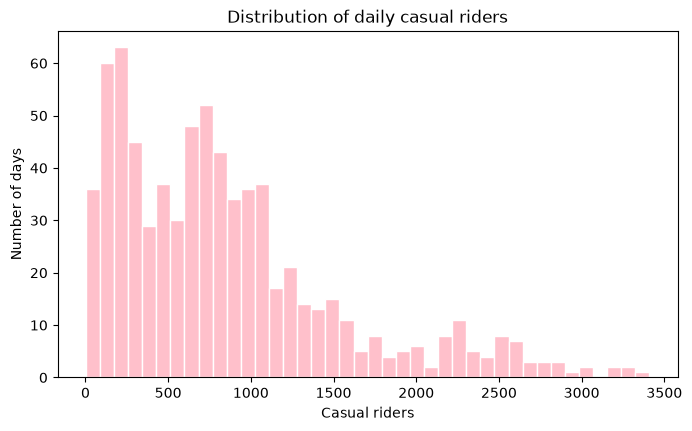

mean: 848.2  median: 713.0  skewness: 1.27


In [ ]:
#4a - - claude was used for this part cause I had no idea how to plot this and i kept getting errors

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(bike["casual"], bins=40, edgecolor="white", color = 'pink')
ax.set_xlabel("Casual riders")
ax.set_ylabel("Number of days")
ax.set_title("Distribution of daily casual riders")
plt.show()

print("mean:", round(bike["casual"].mean(), 1), " median:", bike["casual"].median(), " skewness:", round(bike["casual"].skew(), 2))

the plot is right skewed 

R^2: 0.6291   negative predictions: 28


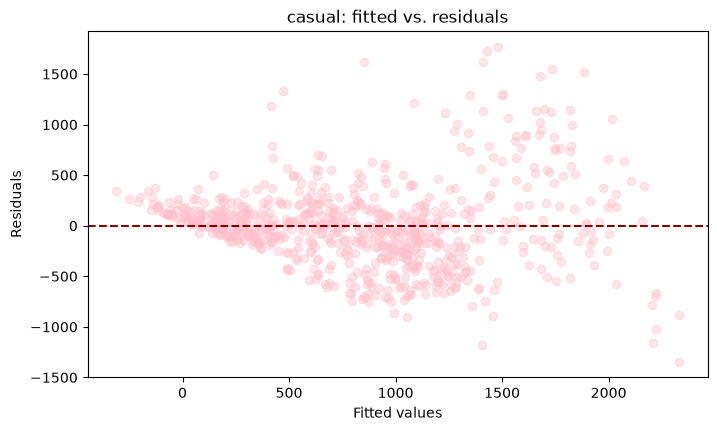

In [ ]:
#4b
Xb = bike[["temp", "hum", "windspeed", "workingday"]]
mb = LinearRegression().fit(Xb, bike["casual"])
fitted = mb.predict(Xb)
resid = bike["casual"] - fitted
print("R^2:", round(mb.score(Xb, bike["casual"]), 4), "  negative predictions:", (fitted < 0).sum())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(fitted, resid, alpha=0.4, color = 'pink')
ax.axhline(0, color="maroon", linestyle="--")
ax.set_xlabel("Fitted values")
ax.set_ylabel("Residuals")
ax.set_title("casual: fitted vs. residuals")
plt.show()

it shows a triangular shape where they fan out the higher the fitted values are. it also predicts negative rider counts which isnt possible.

R^2: 0.6602


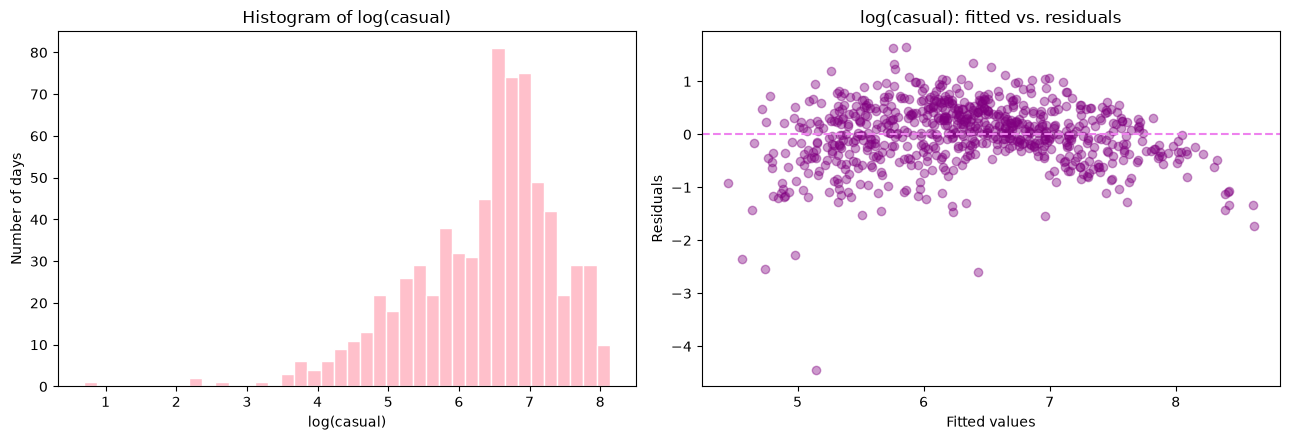

skewness of log(casual): -0.97


In [ ]:
#4c 
log_casual = np.log(bike["casual"])

mlog = LinearRegression().fit(Xb, log_casual)
fitted_log = mlog.predict(Xb)
resid_log = log_casual - fitted_log
print("R^2:", round(mlog.score(Xb, log_casual), 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(log_casual, bins=40, edgecolor="white", color = 'pink')
axes[0].set_xlabel("log(casual)")
axes[0].set_ylabel("Number of days")
axes[0].set_title("Histogram of log(casual)")
axes[1].scatter(fitted_log, resid_log, alpha=0.4, color = 'purple')
axes[1].axhline(0, color="violet", linestyle="--")
axes[1].set_xlabel("Fitted values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("log(casual): fitted vs. residuals")
plt.tight_layout()
plt.show()

print("skewness of log(casual):", round(log_casual.skew(), 2))

the triangle shaoe isnt there anymore and is spread out more evenly and the histogram is now left skewed, which means that it slightly overcorrected.

4d

yes because a positive varuable with a long right tail whose variability grows with its mean is when log transformation is recommended and the plots confirms this because the model doesnt predict negatve couunts anymore. it does overpredict so its not a permanent fix but it is better than the orginal models. keplers law says that taking ogs of both varuables shouldve turned the relationship into a straight line. in these plots the log us only aplied to the response with no law behind it so it can improve the behavior but not the actual fit
